# Comprehensive EDA: The Berka Dataset
## Objective
To perform a deep relational analysis of the Czech Bank dataset. We will explore demographics, loan risk, account activity, and merge tables to create a comprehensive 'Customer 360' view.


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style='darkgrid')
plt.rcParams['figure.figsize'] = (12, 6)


## 1. Data Loading & Schema Inspection


In [14]:
berka_dir = 'data/berka/'
tables = ['account', 'client', 'disp', 'district', 'loan', 'trans', 'card']
dfs = {}

if os.path.exists(berka_dir):
    for tbl in tables:
        filepath = os.path.join(berka_dir, f'{tbl}.csv')
        if os.path.exists(filepath):
            # Sometimes it's comma separated after our fix, sometimes semicolon. Let's try comma first.
            try:
                df = pd.read_csv(filepath)
                if len(df.columns) == 1: # Fallback to semicolon if read as a single column
                    df = pd.read_csv(filepath, sep=';')
                dfs[tbl] = df
                print(f'{tbl.upper():<10} | Shape: {df.shape}')
            except Exception as e:
                print(f'Error loading {tbl}: {e}')
else:
    print('Berka directory not found.')


ACCOUNT    | Shape: (4500, 4)
CLIENT     | Shape: (5369, 3)
DISP       | Shape: (5369, 4)
DISTRICT   | Shape: (77, 16)
LOAN       | Shape: (682, 7)


/tmp/ipykernel_38834/3771728133.py:13: DtypeWarning: Columns (8: bank) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filepath, sep=';')


TRANS      | Shape: (1056320, 10)
CARD       | Shape: (892, 4)


## 2. Deep Dive: Client Demographics
The `birth_number` in the Czech system encodes both birth date and gender. Women have 50 added to the month of their birth.


/tmp/ipykernel_38834/4251161055.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=client, x='Gender', ax=ax[1], palette='pastel')


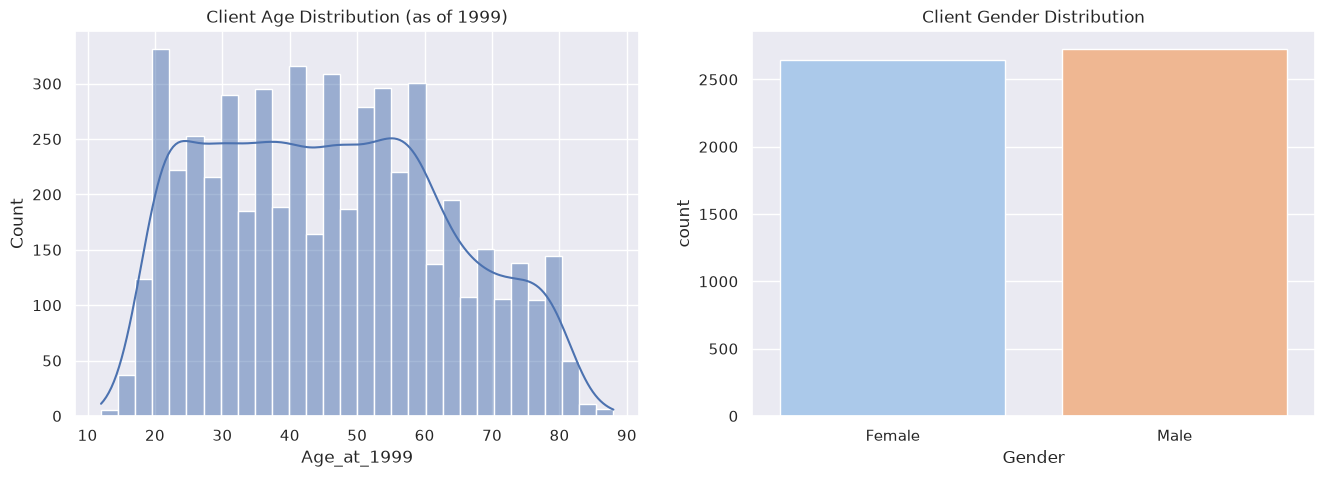

In [15]:
if 'client' in dfs:
    client = dfs['client'].copy()
    
    # Function to extract gender and birth year/month
    def parse_birth_number(bn):
        s = str(bn)
        year = int('19' + s[:2])
        month = int(s[2:4])
        if month > 50:
            gender = 'Female'
            month -= 50
        else:
            gender = 'Male'
        return pd.Series({'Gender': gender, 'BirthYear': year})
    
    client[['Gender', 'BirthYear']] = client['birth_number'].apply(parse_birth_number)
    client['Age_at_1999'] = 1999 - client['BirthYear'] # Dataset ends in 1999
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    sns.histplot(client['Age_at_1999'], bins=30, ax=ax[0], kde=True)
    ax[0].set_title('Client Age Distribution (as of 1999)')
    
    sns.countplot(data=client, x='Gender', ax=ax[1], palette='pastel')
    ax[1].set_title('Client Gender Distribution')
    plt.show()


## 3. Deep Dive: Loan Risk Analysis
Understanding default rates and their correlation with loan amounts.


/tmp/ipykernel_38834/1252678287.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=loan, x='Risk_Status', palette='Set2', ax=ax[0])
/tmp/ipykernel_38834/1252678287.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=loan, x='Risk_Status', y='amount', palette='Set2', ax=ax[1])


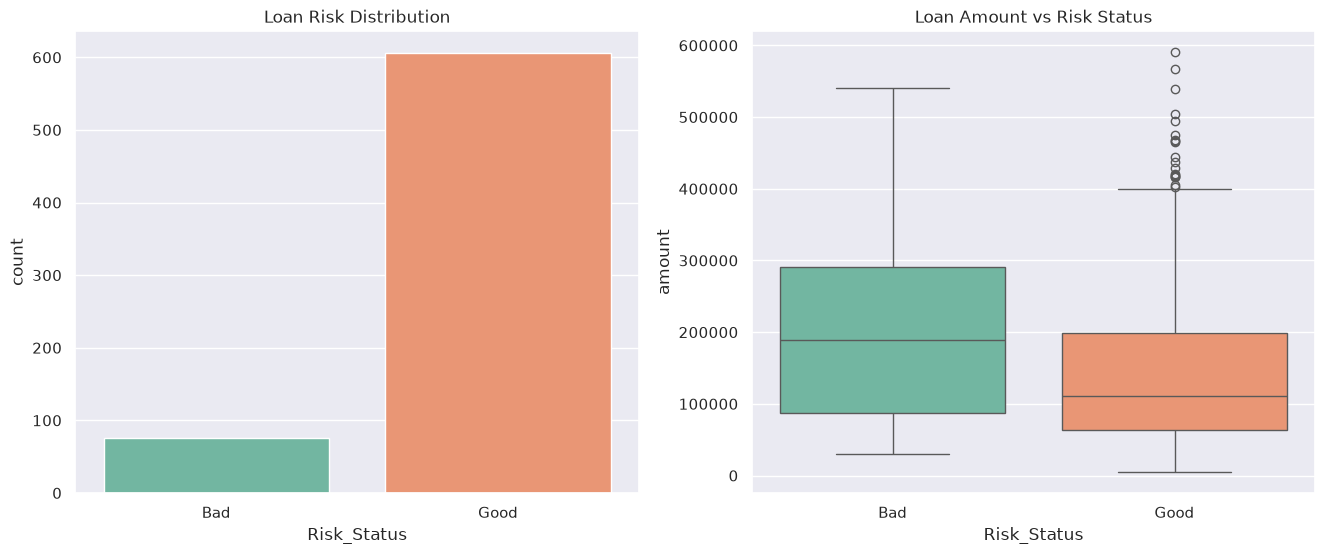

In [16]:
if 'loan' in dfs:
    loan = dfs['loan'].copy()
    # Status: A/C = Good (Finished/Running OK), B/D = Bad (Finished Default/Running in Debt)
    loan['Risk_Status'] = loan['status'].map({'A': 'Good', 'C': 'Good', 'B': 'Bad', 'D': 'Bad'})
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    sns.countplot(data=loan, x='Risk_Status', palette='Set2', ax=ax[0])
    ax[0].set_title('Loan Risk Distribution')
    
    sns.boxplot(data=loan, x='Risk_Status', y='amount', palette='Set2', ax=ax[1])
    ax[1].set_title('Loan Amount vs Risk Status')
    plt.show()


## 4. Deep Dive: Transaction Patterns
Analyzing cash vs digital behavior.


/tmp/ipykernel_38834/779051886.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=trans, y='operation', order=trans['operation'].value_counts().index, palette='viridis')


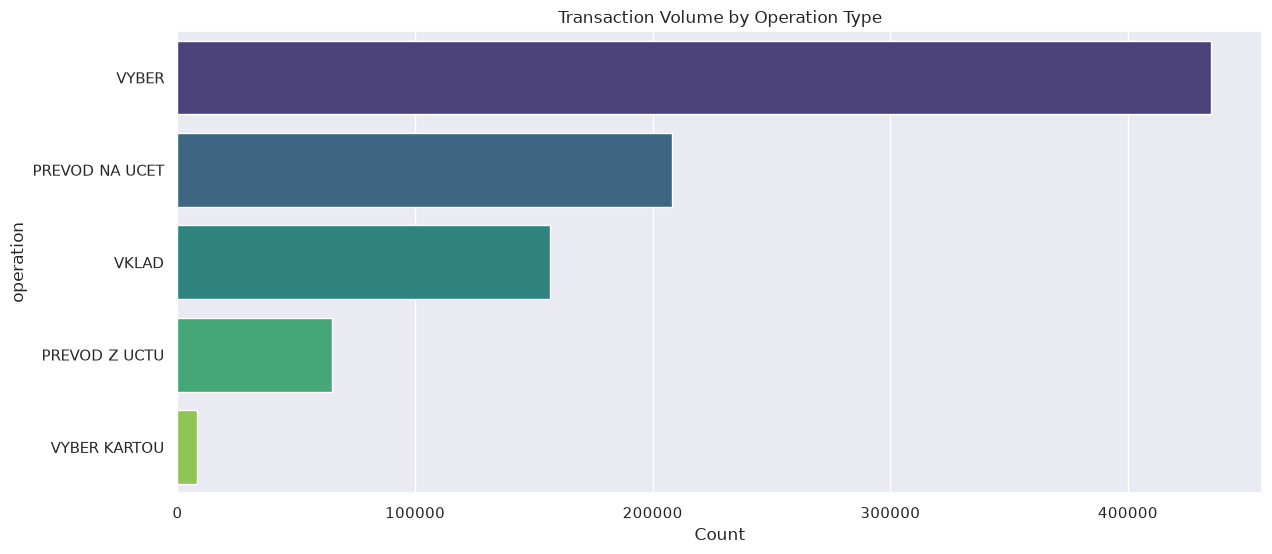

In [17]:
if 'trans' in dfs:
    trans = dfs['trans'].copy()
    
    # Transaction operation types
    plt.figure(figsize=(14, 6))
    sns.countplot(data=trans, y='operation', order=trans['operation'].value_counts().index, palette='viridis')
    plt.title('Transaction Volume by Operation Type')
    plt.xlabel('Count')
    plt.show()


## 5. Relational Merging: Creating the 'Customer 360' View
We merge Client -> Disposition (Owner) -> Account -> Loan to see if demographics influence loan defaults.


Customer 360 View Shape: (682, 19)


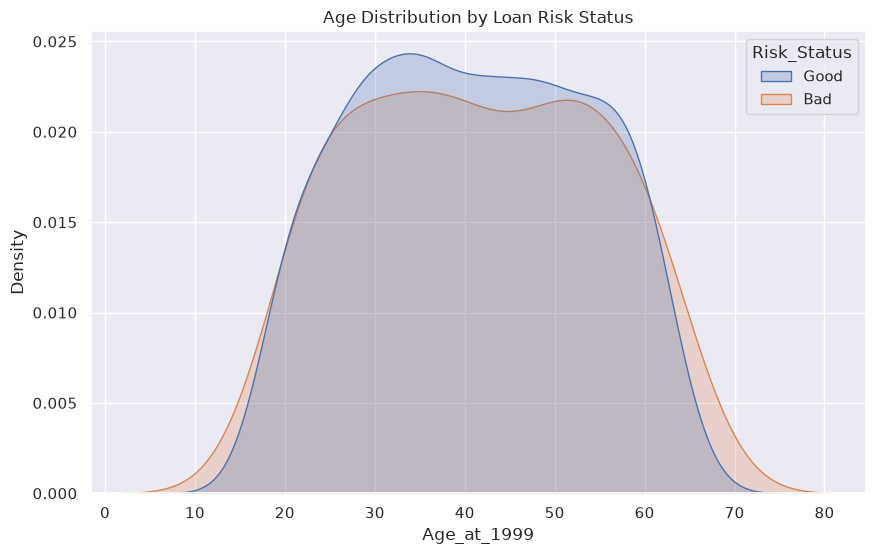

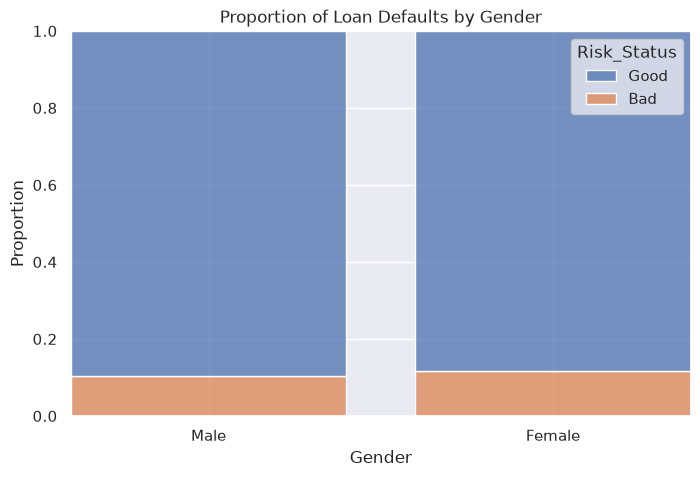

In [18]:
if all(k in dfs for k in ['client', 'disp', 'account', 'loan']):
    # Get owners only
    owners = dfs['disp'][dfs['disp']['type'] == 'OWNER']
    
    # Merge client info (using the parsed client df from Section 2 if available)
    client_owners = pd.merge(owners, client if 'Age_at_1999' in client.columns else dfs['client'], on='client_id')
    
    # Merge with accounts and loans
    acc_loan = pd.merge(dfs['account'], loan if 'Risk_Status' in loan.columns else dfs['loan'], on='account_id')
    customer_360 = pd.merge(client_owners, acc_loan, on='account_id')
    
    print(f'Customer 360 View Shape: {customer_360.shape}')
    
    # Visualize Age vs Loan Default
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=customer_360, x='Age_at_1999', hue='Risk_Status', common_norm=False, fill=True)
    plt.title('Age Distribution by Loan Risk Status')
    plt.show()
    
    # Gender vs Risk
    plt.figure(figsize=(8, 5))
    sns.histplot(data=customer_360, x='Gender', hue='Risk_Status', multiple='fill', shrink=.8)
    plt.title('Proportion of Loan Defaults by Gender')
    plt.ylabel('Proportion')
    plt.show()


## Summary & Insights
1. The demographic extraction (Age/Gender) from `birth_number` allows us to profile customers accurately.
2. Loan defaults ('B' and 'D' statuses) are a clear indicator of financial distress and serve as a brilliant proxy for a 'Risk' or 'Credit-Seeking' segment in our final clustering model.
3. Combining these tables provides a far richer behavioral dataset (Cards, Loans, Demographics, Transactions) than transaction data alone.


## 6. Data Normalization for Clustering
Just as with the primary dataset, preparing the Berka data for clustering requires scaling.

Features like `amount` (from loans or transactions) operate on vastly different scales compared to `Age_at_1999`. We will apply **StandardScaler** to standardize these ranges. This is critical for both Track A (Traditional Clustering) and Track B (Representation Learning) in your project plan.


In [19]:
from sklearn.preprocessing import StandardScaler

if 'customer_360' in locals() and not customer_360.empty:
    # Select numerical features for scaling from the merged Customer 360 view
    features_to_scale = ['Age_at_1999', 'amount']
    features_to_scale = [f for f in features_to_scale if f in customer_360.columns]
    
    df_clean = customer_360.dropna(subset=features_to_scale).copy()
    
    scaler = StandardScaler()
    df_scaled = df_clean.copy()
    df_scaled[features_to_scale] = scaler.fit_transform(df_clean[features_to_scale])
    
    print("--- Original Customer 360 Data Summary ---")
    display(df_clean[features_to_scale].describe())
    
    print("\n--- Scaled Customer 360 Data Summary (Mean ≈ 0, Std ≈ 1) ---")
    display(df_scaled[features_to_scale].describe())
    
    print("\nData is now normalized and ready for clustering algorithms!")


--- Original Customer 360 Data Summary ---


,Age_at_1999,amount
count,682.000000,682.000000
mean,40.901760,151410.175953
std,12.688891,113372.406310
min,19.000000,4980.000000
25%,30.000000,66732.000000
50%,41.000000,116928.000000
75%,52.000000,210654.000000
max,64.000000,590820.000000



--- Scaled Customer 360 Data Summary (Mean ≈ 0, Std ≈ 1) ---


,Age_at_1999,amount
count,6.820000e+02,6.820000e+02
mean,2.396258e-16,-1.041852e-16
std,1.000734e+00,1.000734e+00
min,-1.727325e+00,-1.292534e+00
25%,-8.597884e-01,-7.474511e-01
50%,7.747925e-03,-3.043729e-01
75%,8.752842e-01,5.229430e-01
max,1.821687e+00,3.878654e+00



Data is now normalized and ready for clustering algorithms!
